# Spotify Popularity / Hit Modeling

## Objective
Predict continuous snapshot popularity using leakage-aware regression, compare against a simple baseline, and explain model behavior on unseen artists. No arbitrary hit threshold is required.

## Dataset overview
The source is Yamac Eren Ay's [Spotify Dataset 1921–2020, 600k+ Tracks](https://www.kaggle.com/datasets/yamaerenay/spotify-dataset-19212020-600k-tracks), version 1.
The actual release-year range is audited below rather than inferred from the title. This is a historical catalog snapshot with track metadata, Spotify audio descriptors, and popularity (0–100). It has no track-level genre, album, listener histories, or contemporaneous chart labels.

Run `python scripts/download_data.py` and `python scripts/prepare_data.py` first. Every notebook runs independently from the project root. Source hashes and cleaning counts live in `data/processed/quality_report.json`.

## Imports

In [1]:
from pathlib import Path
import json
import platform
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

RANDOM_STATE = 42
ROOT = Path.cwd()
if not (ROOT / "scripts/prepare_data.py").exists():
    raise RuntimeError("Open Jupyter from the project root.")
REPORTS = ROOT / "reports"
REPORTS.mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})
pd.set_option("display.max_columns", 15)
assert Path(sys.prefix).name == "spotify", "Select the Python (spotify) kernel."
display(Markdown(f"**Runtime:** Python {platform.python_version()} · spotify environment"))
AUDIO_FEATURES = ["danceability", "energy", "valence", "acousticness",
                  "instrumentalness", "speechiness", "liveness", "loudness", "tempo"]

**Runtime:** Python 3.14.7 · spotify environment

## Data loading and cleaning

In [2]:
tracks = pd.read_parquet(ROOT / "data/processed/tracks.parquet")
quality = json.loads((ROOT / "data/processed/quality_report.json").read_text())
display(pd.Series({"raw_rows": quality["raw_rows"],
                   "processed_rows": len(tracks),
                   "first_year": quality["year_min"], "last_year": quality["year_max"],
                   "repeated_artist_title_rows": quality["repeated_artist_title_rows"]}, name="Data audit"))
assert tracks.id.is_unique

raw_rows                      586672
processed_rows                586601
first_year                      1900
last_year                       2021
repeated_artist_title_rows     62393
Name: Data audit, dtype: int64

Shared preparation removes exact duplicates and repeated Spotify IDs, and drops rows without usable identity. Invalid numeric values become missing; unknown zero tempo becomes missing. Dates keep their original precision in `release_date`, with a derived year for grouping. Long recordings are flagged, not arbitrarily deleted. Unicode names are retained. Distinct IDs with the same artist/title remain in the shared data because editions can differ; modeling and recommendation apply stricter deduplication below. Unobserved recordings cannot be identified without acoustic fingerprints.

## Target, cleaning, and exploratory analysis
The target is the source's 0–100 popularity score at collection time. It is neither lifetime streams nor future success. To make artist separation strict and understandable, restrict this experiment to single-artist recordings, deduplicate artist/title editions, and sample up to 100,000 tracks. Collaborative tracks are excluded only from this notebook; their row impact is reported. Missing popularity is excluded, never imputed.

shared_tracks                          586601
single_artist_tracks                   479685
unique_labeled_single_artist_tracks    427392
model_sample                           100000
dtype: int64

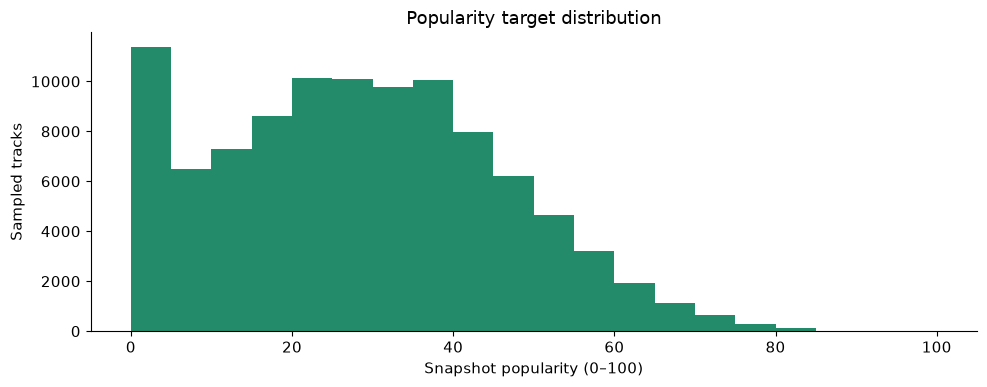

In [3]:
import ast
single_artist = tracks.id_artists.map(ast.literal_eval).str.len().eq(1)
eligible = tracks.loc[single_artist].drop_duplicates("recording_group").dropna(subset=["popularity"]).copy()
model_data = eligible.sample(n=min(100000, len(eligible)), random_state=42).reset_index(drop=True)
model_data["log_duration"] = np.log1p(model_data.duration_min)
display(pd.Series({"shared_tracks": len(tracks), "single_artist_tracks": int(single_artist.sum()),
                   "unique_labeled_single_artist_tracks": len(eligible), "model_sample": len(model_data)}))
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(model_data.popularity, bins=np.arange(0, 105, 5), color="#238b69")
ax.set(title="Popularity target distribution", xlabel="Snapshot popularity (0–100)", ylabel="Sampled tracks")
plt.tight_layout()
plt.show()

Popularity is bounded and unevenly distributed, so errors on rare high-popularity tracks may differ from average error. We use regression rather than relabeling the upper tail as universal 'hits'. Subsampling controls runtime and does not balance or alter the target distribution deliberately.

## Train, validation, and test separation
GroupShuffleSplit allocates artists, not individual tracks: approximately 70%/15%/15% of artists form training/validation/test sets. A single artist cannot occur in multiple sets, preventing memorization of artist-specific recordings. Row percentages need not be exact. Median imputation and standardization are fit only inside each training pipeline. IDs, titles, artist identity, cluster labels, and target-derived variables are excluded from predictors.

Audio-only models test signal in musical descriptors. A separate gradient-boosting model adds release year, which is available metadata but can exploit snapshot recency bias. The task is cross-sectional prediction for unseen artists, not prospective hit forecasting. We select by validation MAE and touch the test set only after selection.

In [4]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.base import clone
from threadpoolctl import threadpool_limits

first_split = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
development_positions, test_positions = next(first_split.split(model_data, groups=model_data.primary_artist_id))
development = model_data.iloc[development_positions]
test_data = model_data.iloc[test_positions]
second_split = GroupShuffleSplit(n_splits=1, test_size=0.15/0.85, random_state=42)
train_positions, validation_positions = next(second_split.split(development, groups=development.primary_artist_id))
training = development.iloc[train_positions]
validation = development.iloc[validation_positions]
artist_sets = [set(frame.primary_artist_id) for frame in [training, validation, test_data]]
assert not artist_sets[0] & artist_sets[1]
assert not artist_sets[0] & artist_sets[2]
assert not artist_sets[1] & artist_sets[2]
display(pd.DataFrame({"split": ["train", "validation", "test"],
                      "rows": [len(training), len(validation), len(test_data)],
                      "artists": [len(group) for group in artist_sets]}))
audio_predictors = AUDIO_FEATURES + ["log_duration"]
predictors_with_year = audio_predictors + ["year"]

,split,rows,artists
0,train,70228,21345
1,validation,15125,4575
2,test,14647,4575


## Models and metrics
The median dummy is a useful MAE baseline: it ignores every feature. Ridge regression estimates an additive linear relationship with shrinkage to stabilize correlated coefficients. Histogram gradient boosting learns nonlinear interactions by adding shallow trees that correct prior errors. Hyperparameters are fixed modestly to avoid a wide search; internal early stopping is disabled so no accidental row-wise validation split crosses artist groups.

MAE is the average absolute error in popularity points and determines selection. RMSE penalizes large errors more heavily. R² measures improvement over predicting the evaluated set's mean; it can be negative. Baselines and model comparisons are necessary before interpreting feature importance.

In [5]:
models = {
    "Median baseline": (audio_predictors, make_pipeline(SimpleImputer(strategy="median"), DummyRegressor(strategy="median"))),
    "Ridge audio": (audio_predictors, make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10))),
    "Boosting audio": (audio_predictors, make_pipeline(SimpleImputer(strategy="median"), HistGradientBoostingRegressor(max_iter=150, max_leaf_nodes=15, l2_regularization=10, early_stopping=False, random_state=42))),
    "Boosting audio + year": (predictors_with_year, make_pipeline(SimpleImputer(strategy="median"), HistGradientBoostingRegressor(max_iter=150, max_leaf_nodes=15, l2_regularization=10, early_stopping=False, random_state=42)))
}

def regression_metrics(actual, predictions):
    return {"MAE": mean_absolute_error(actual, predictions),
            "RMSE": root_mean_squared_error(actual, predictions),
            "R2": r2_score(actual, predictions)}

validation_scores = []
with threadpool_limits(limits=4):
    for name, (predictors, model) in models.items():
        model.fit(training[predictors], training.popularity)
        predictions = model.predict(validation[predictors])
        validation_scores.append({"model": name, **regression_metrics(validation.popularity, predictions)})
validation_scores = pd.DataFrame(validation_scores).set_index("model").sort_values("MAE")
display(validation_scores.round(3))
winner = validation_scores.index[0]

,MAE,RMSE,R2
model,,,
Boosting audio + year,10.308,13.364,0.425
Boosting audio,11.959,14.964,0.279
Ridge audio,12.848,15.919,0.184
Median baseline,14.437,17.640,-0.002


The audio-only versus year-augmented comparison isolates the practical value of release metadata. A large gain from year is evidence that snapshot recency structure matters, not evidence that release year causes popularity. Model selection is complete at this point.

## Final test results and error analysis

,MAE,RMSE,R2
Boosting audio + year,10.232,13.252,0.407
Median baseline,14.302,17.281,-0.009


,tracks,MAE
target_band,,
"(-1, 20]",4983,11.343
"(20, 40]",6076,6.490
"(40, 60]",3093,13.024
"(60, 80]",481,27.136
"(80, 100]",14,41.130


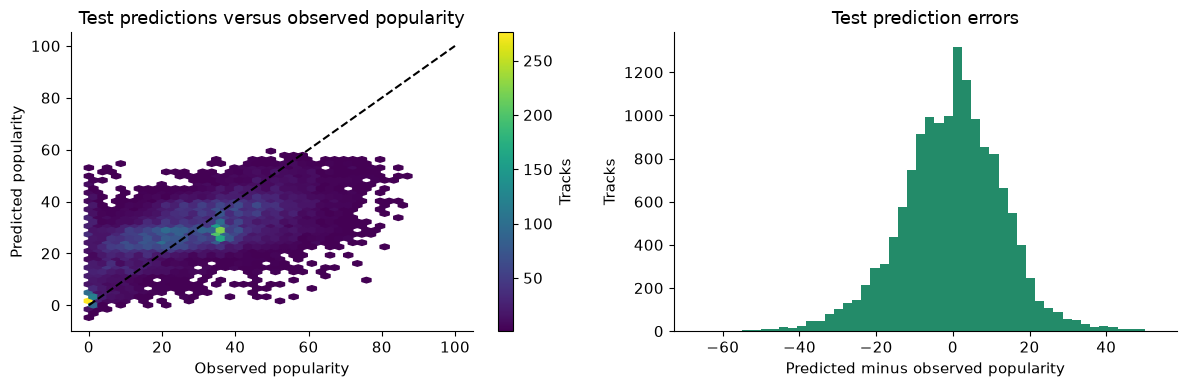

In [6]:
selected_features, selected_template = models[winner]
final_model = clone(selected_template)
baseline = clone(models["Median baseline"][1])
with threadpool_limits(limits=4):
    final_model.fit(development[selected_features], development.popularity)
    baseline.fit(development[audio_predictors], development.popularity)
    test_predictions = final_model.predict(test_data[selected_features])
    baseline_predictions = baseline.predict(test_data[audio_predictors])
test_scores = pd.DataFrame({winner: regression_metrics(test_data.popularity, test_predictions),
                            "Median baseline": regression_metrics(test_data.popularity, baseline_predictions)}).T
display(test_scores.round(3))
errors = test_data[["primary_artist_id", "popularity", "year"]].copy()
errors["prediction"] = test_predictions
errors["absolute_error"] = np.abs(errors.popularity - errors.prediction)
errors["target_band"] = pd.cut(errors.popularity, [-1, 20, 40, 60, 80, 100])
display(errors.groupby("target_band", observed=True).agg(tracks=("absolute_error", "size"), MAE=("absolute_error", "mean")).round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
hexplot = axes[0].hexbin(errors.popularity, errors.prediction, gridsize=35, mincnt=1, cmap="viridis")
axes[0].plot([0, 100], [0, 100], "--", color="black")
axes[0].set(title="Test predictions versus observed popularity", xlabel="Observed popularity", ylabel="Predicted popularity")
fig.colorbar(hexplot, ax=axes[0], label="Tracks")
axes[1].hist(errors.prediction-errors.popularity, bins=50, color="#238b69")
axes[1].set(title="Test prediction errors", xlabel="Predicted minus observed popularity", ylabel="Tracks")
plt.tight_layout()
fig.savefig(REPORTS / "04_errors.png", dpi=120)
plt.show()

The diagonal represents perfect prediction; the plot reveals compression toward typical scores. Test MAE rises to about 27 points for observed popularity 60–80 and 41 points for 80–100, with only 14 examples in the latter band. The model is therefore a poor detector of rare major hits despite improving average error. These diagnostics are not used for further tuning. Held-out artists still come from the same historical collection process, so the evaluation cannot establish future performance. Predictions are unconstrained regression outputs and may fall outside 0–100; the reported metrics use these raw predictions consistently.

## Explainability: permutation importance
Permutation importance shuffles one predictor at a time and measures the increase in MAE while holding the fitted model fixed. Use a seeded 2,000-row test subset and five repetitions for practical runtime. Positive values mean the model relied on that feature; negative values can arise from noise. Correlated features can substitute for one another and understate individual importance. Repetition error bars describe shuffle variability, not population confidence intervals. No causal interpretation is warranted.

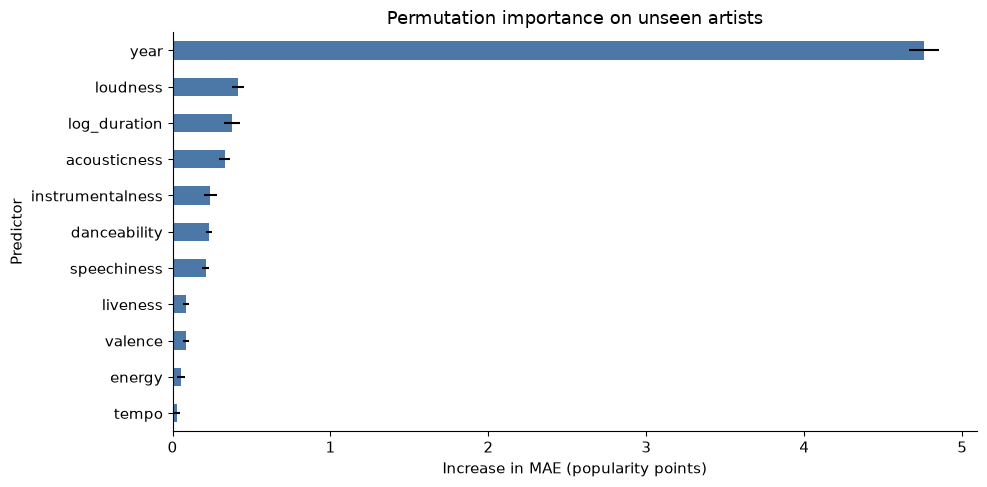

,feature,MAE_increase,shuffle_sd
10,year,4.755,0.095
7,loudness,0.414,0.036
9,log_duration,0.377,0.051
3,acousticness,0.330,0.034
4,instrumentalness,0.238,0.040
0,danceability,0.231,0.021
5,speechiness,0.209,0.020
6,liveness,0.086,0.020
2,valence,0.085,0.017
1,energy,0.054,0.024


**Selected model: Boosting audio + year.** Test MAE is **10.23** versus **14.30** for the baseline; R² is **0.407**. Weighting each artist equally gives MAE **10.43**, with an artist-bootstrap 95% interval **[10.22, 10.65]**. This interval concerns the artist-weighted metric, not the track-weighted headline MAE.

In [7]:
from sklearn.inspection import permutation_importance
explain_data = test_data.sample(n=min(2000, len(test_data)), random_state=42)
with threadpool_limits(limits=4):
    importance = permutation_importance(final_model, explain_data[selected_features], explain_data.popularity,
                                       scoring="neg_mean_absolute_error", n_repeats=5, random_state=42, n_jobs=1)
importance_table = pd.DataFrame({"feature": selected_features, "MAE_increase": importance.importances_mean,
                                 "shuffle_sd": importance.importances_std}).sort_values("MAE_increase")
ax = importance_table.plot.barh(x="feature", y="MAE_increase", xerr="shuffle_sd", legend=False, color="#4c78a8")
ax.set(title="Permutation importance on unseen artists", xlabel="Increase in MAE (popularity points)", ylabel="Predictor")
plt.tight_layout()
plt.show()
display(importance_table.sort_values("MAE_increase", ascending=False).round(3))
artist_errors = errors.groupby("primary_artist_id").absolute_error.mean().to_numpy()
rng = np.random.default_rng(42)
bootstrap = [rng.choice(artist_errors, size=len(artist_errors), replace=True).mean() for _ in range(2000)]
artist_interval = np.quantile(bootstrap, [0.025, 0.975])
summary = {"selected_model": winner, "test_rows": len(test_data), "test_artists": len(artist_errors),
           "validation": validation_scores.reset_index().to_dict(orient="records"),
           "test": test_scores.reset_index(names="model").to_dict(orient="records"),
           "artist_weighted_MAE": float(artist_errors.mean()), "artist_MAE_ci": artist_interval.tolist(),
           "top_permutation_feature": importance_table.iloc[-1].feature}
(REPORTS / "model_metrics.json").write_text(json.dumps(summary, indent=2))
display(Markdown(f"**Selected model: {winner}.** Test MAE is **{test_scores.loc[winner, 'MAE']:.2f}** versus **{test_scores.loc['Median baseline', 'MAE']:.2f}** for the baseline; R² is **{test_scores.loc[winner, 'R2']:.3f}**. Weighting each artist equally gives MAE **{artist_errors.mean():.2f}**, with an artist-bootstrap 95% interval **[{artist_interval[0]:.2f}, {artist_interval[1]:.2f}]**. This interval concerns the artist-weighted metric, not the track-weighted headline MAE."))

## Interpretation, limitations, and conclusion
These models quantify predictive signal available in descriptors and release metadata. Popularity also depends on marketing, audience, playlists, geography, and time since release, which are largely absent. Single-artist filtering limits generalization to collaborations; metadata errors and reissues remain. Regression predictions are not calibrated probabilities of becoming a hit. Permutation rankings explain reliance of this fitted model, not mechanisms in the music industry. A prospective evaluation requires repeated dated popularity snapshots and a temporal split with features available at the forecast date.